Fetching and standardizing Wheat Seeds dataset...
Training GMM space exploration...
Training Multi-Layer Perceptron (Neural Network)...
Generating comparative analysis figure...


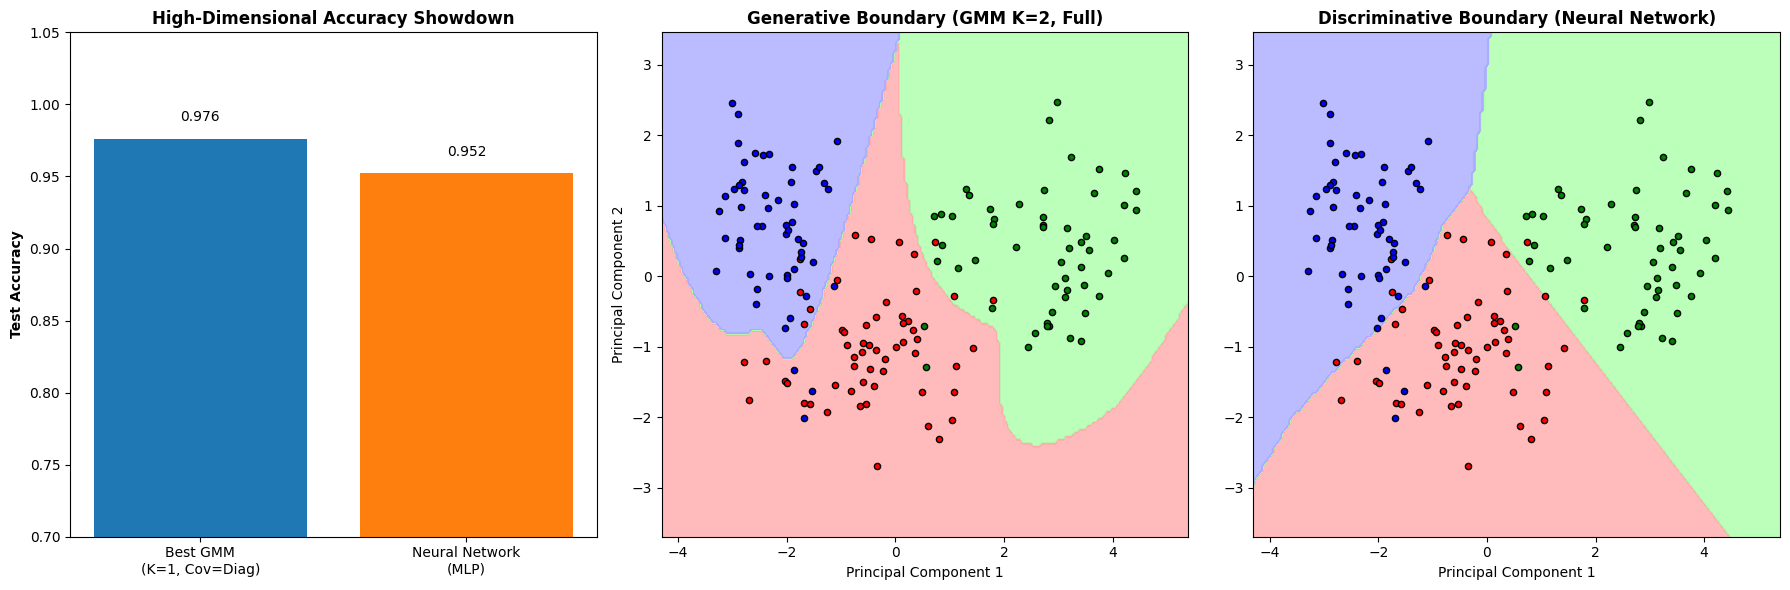

Execution complete.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.colors as mcolors
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
import warnings

warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# 1. Data Loading & Preprocessing
# ---------------------------------------------------------
print("Fetching and standardizing Wheat Seeds dataset...")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"
df = pd.read_csv(url, sep=r'\s+', header=None)

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values - 1

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X = (X - X_mean) / X_std

np.random.seed(42)
indices = np.random.permutation(len(X))
split_idx = int(len(X) * 0.8)
train_idx, test_idx = indices[:split_idx], indices[split_idx:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# ---------------------------------------------------------
# 2. Mathematical Foundations (Custom GMM)
# ---------------------------------------------------------
def log_multivariate_normal(X, mean, cov):
    D = X.shape[1]
    cov = cov + np.eye(D) * 1e-6
    sign, logdet = np.linalg.slogdet(cov)
    inv_cov = np.linalg.inv(cov)
    diff = X - mean
    maha = np.sum((diff @ inv_cov) * diff, axis=1)
    return -0.5 * (D * np.log(2 * np.pi) + logdet + maha)

class CustomGMM:
    def __init__(self, n_components=1, cov_type='full', max_iter=100, tol=1e-4):
        self.K = n_components
        self.cov_type = cov_type
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X):
        N, D = X.shape
        np.random.seed(42)
        random_indices = np.random.choice(N, self.K, replace=False)
        self.means = X[random_indices].copy()
        self.covs = np.array([np.eye(D) for _ in range(self.K)])
        self.pi = np.ones(self.K) / self.K

        log_likelihood_old = -np.inf

        for iteration in range(self.max_iter):
            log_resps = np.zeros((N, self.K))
            for k in range(self.K):
                log_resps[:, k] = np.log(self.pi[k]) + log_multivariate_normal(X, self.means[k], self.covs[k])

            log_resp_norm = np.logaddexp.reduce(log_resps, axis=1)
            self.log_likelihood_ = np.sum(log_resp_norm)
            resps = np.exp(log_resps - log_resp_norm[:, np.newaxis])

            if np.abs(self.log_likelihood_ - log_likelihood_old) < self.tol:
                break
            log_likelihood_old = self.log_likelihood_

            Nk = np.sum(resps, axis=0)
            self.pi = Nk / N

            for k in range(self.K):
                self.means[k] = np.sum(resps[:, k, np.newaxis] * X, axis=0) / Nk[k]
                diff = X - self.means[k]
                cov = (resps[:, k, np.newaxis] * diff).T @ diff / Nk[k]

                if self.cov_type == 'full': self.covs[k] = cov
                elif self.cov_type == 'diag': self.covs[k] = np.diag(np.diag(cov))
                elif self.cov_type == 'spherical': self.covs[k] = np.eye(D) * np.mean(np.diag(cov))

    def score_samples(self, X):
        N = X.shape[0]
        log_resps = np.zeros((N, self.K))
        for k in range(self.K):
            log_resps[:, k] = np.log(self.pi[k]) + log_multivariate_normal(X, self.means[k], self.covs[k])
        return np.logaddexp.reduce(log_resps, axis=1)

# ---------------------------------------------------------
# 3. Model Training (GMM + Neural Network)
# ---------------------------------------------------------
classes = np.unique(y_train)
k_values_visual = [1, 2, 3]
cov_types = ['spherical', 'diag', 'full']

models_2d_grid = {}
best_gmm_acc = 0
best_gmm_config = ""

print("Training GMM space exploration...")
for cov_type in cov_types:
    for K in k_values_visual:
        models_hd, models_2d = {}, {}

        for c in classes:
            # High-D
            gmm_hd = CustomGMM(n_components=K, cov_type=cov_type)
            gmm_hd.fit(X_train[y_train == c])
            models_hd[c] = gmm_hd

            # 2D PCA
            gmm_2d = CustomGMM(n_components=K, cov_type=cov_type)
            gmm_2d.fit(X_train_pca[y_train == c])
            models_2d[c] = gmm_2d

        models_2d_grid[(K, cov_type)] = models_2d

        # GMM Accuracy Evaluation
        preds = []
        for x in X_test:
            scores = {c: models_hd[c].score_samples(x.reshape(1, -1))[0] for c in classes}
            preds.append(max(scores, key=scores.get))

        acc = np.mean(np.array(preds) == y_test)
        if acc > best_gmm_acc:
            best_gmm_acc = acc
            best_gmm_config = f"K={K}, Cov={cov_type.capitalize()}"

print("Training Multi-Layer Perceptron (Neural Network)...")


# MLP High-Dimensional (Accuracy comparison)
mlp_hd = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
mlp_hd.fit(X_train, y_train)
mlp_acc = mlp_hd.score(X_test, y_test)

# MLP 2D PCA (Boundary comparison)
mlp_2d = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
mlp_2d.fit(X_train_pca, y_train)

# ---------------------------------------------------------
# 4. Visualization Utilities
# ---------------------------------------------------------
colors = ['r', 'g', 'b']
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
mesh_points = np.c_[xx.ravel(), yy.ravel()]
cmap_light = mcolors.ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

# ---------------------------------------------------------
# 5. Figure: GMM Generative vs. MLP Discriminative
# ---------------------------------------------------------
print("Generating comparative analysis figure...")
fig4 = plt.figure(figsize=(18, 6))

# Subplot 1: Accuracy Bar Chart
ax1 = plt.subplot(1, 3, 1)
bars = ax1.bar(['Best GMM\n('+best_gmm_config+')', 'Neural Network\n(MLP)'],
               [best_gmm_acc, mlp_acc], color=['#1f77b4', '#ff7f0e'])
ax1.set_ylim(0.7, 1.05)
ax1.set_ylabel('Test Accuracy', fontweight='bold')
ax1.set_title('High-Dimensional Accuracy Showdown', fontweight='bold')
# Add value labels
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}", ha='center', va='bottom')

# Subplot 2: GMM Decision Boundary (Using K=2, Full as typical best representative)
ax2 = plt.subplot(1, 3, 2)
gmm_rep_models = models_2d_grid[(2, 'full')]
Z_gmm = []
for point in mesh_points:
    scores = {c: gmm_rep_models[c].score_samples(point.reshape(1, -1))[0] for c in classes}
    Z_gmm.append(max(scores, key=scores.get))
Z_gmm = np.array(Z_gmm).reshape(xx.shape)

ax2.contourf(xx, yy, Z_gmm, cmap=cmap_light, alpha=0.8)
for c in classes:
    ax2.scatter(X_train_pca[y_train == c, 0], X_train_pca[y_train == c, 1],
               c=colors[c], edgecolor='k', s=20)
ax2.set_title('Generative Boundary (GMM K=2, Full)', fontweight='bold')
ax2.set_xlabel('Principal Component 1')
ax2.set_ylabel('Principal Component 2')

# Subplot 3: Neural Network Decision Boundary
ax3 = plt.subplot(1, 3, 3)
Z_mlp = mlp_2d.predict(mesh_points).reshape(xx.shape)

ax3.contourf(xx, yy, Z_mlp, cmap=cmap_light, alpha=0.8)
for c in classes:
    ax3.scatter(X_train_pca[y_train == c, 0], X_train_pca[y_train == c, 1],
               c=colors[c], edgecolor='k', s=20)
ax3.set_title('Discriminative Boundary (Neural Network)', fontweight='bold')
ax3.set_xlabel('Principal Component 1')

plt.tight_layout()
plt.show()
print("Execution complete.")

Fetching and standardizing Wheat Seeds dataset...
Training high-dimensional and 2D models. This may take a few seconds...
Generating figure 1 (analytical suite)...


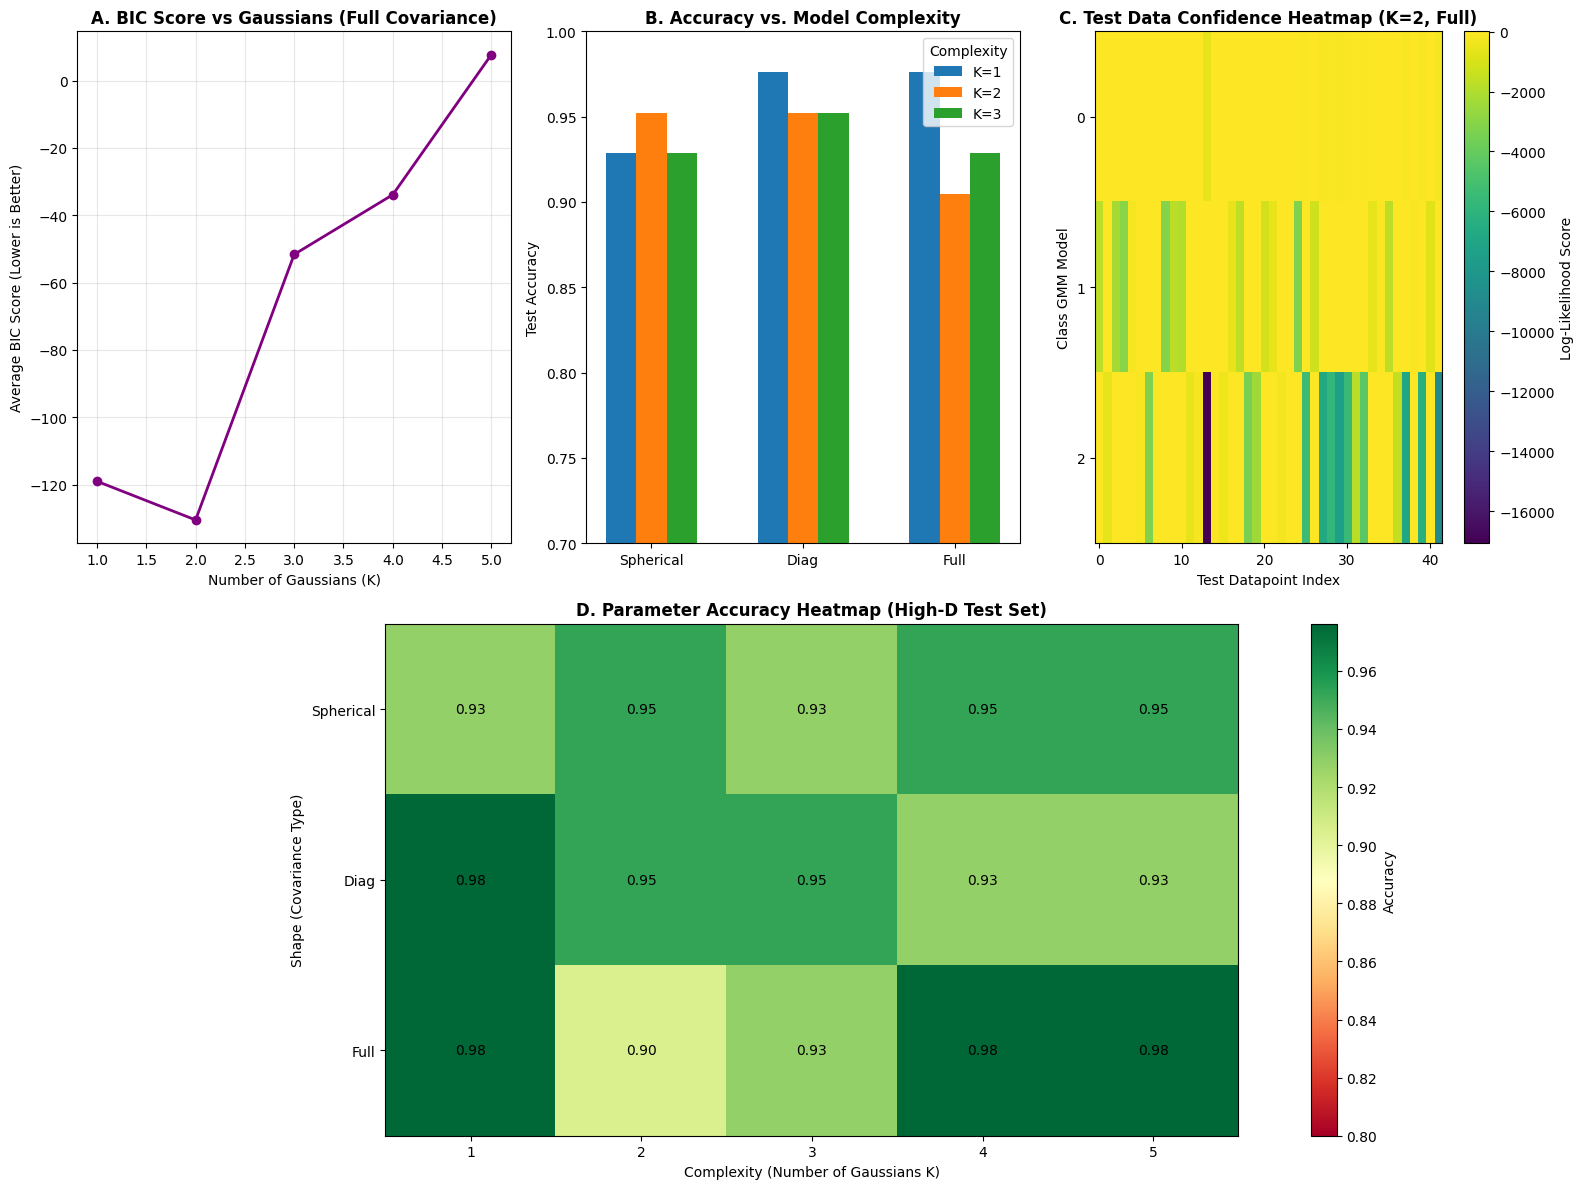

Generating figure 2 (3x3 grid of covariance ellipsoid overlays)...


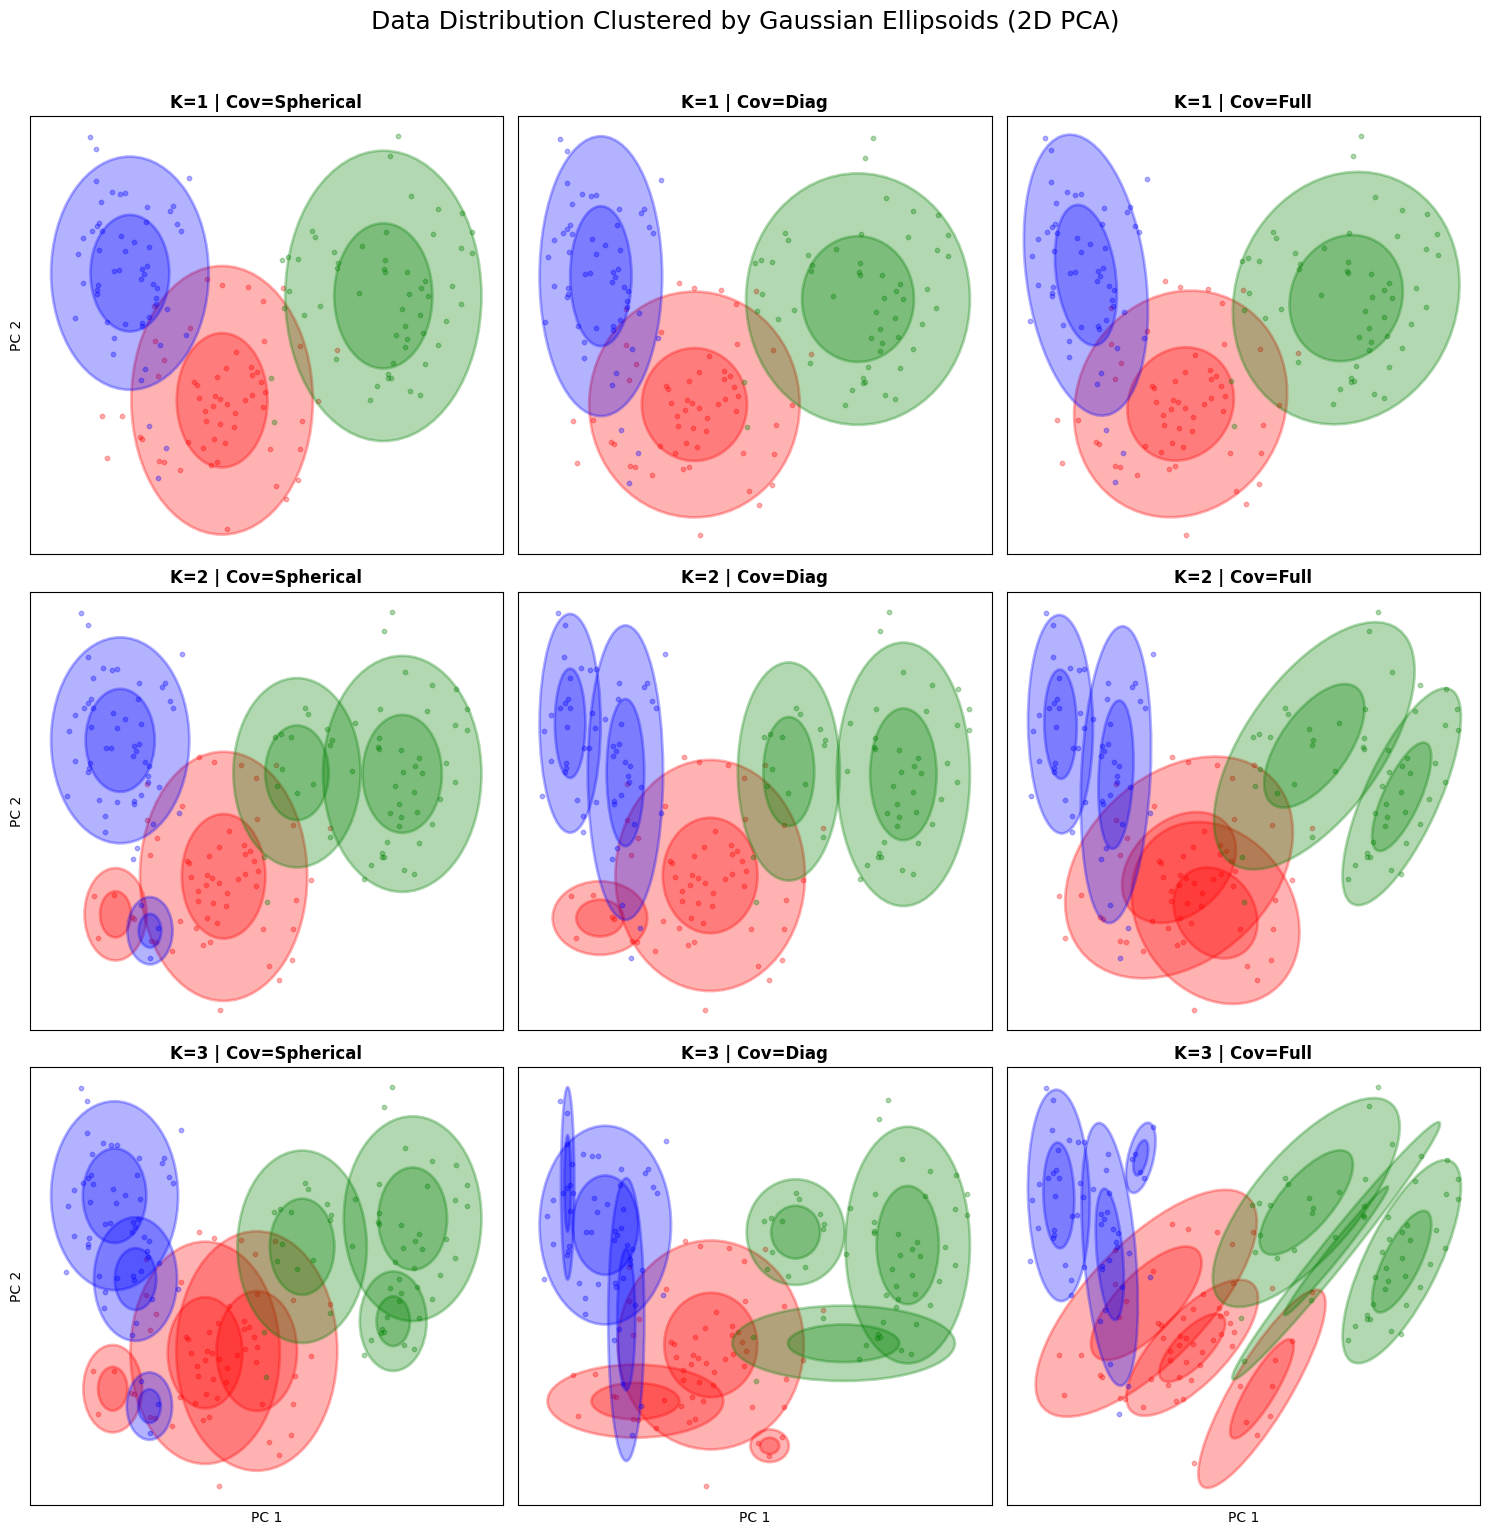

Generating figure 3 (3x3 grid of decision boundary meshplots)...


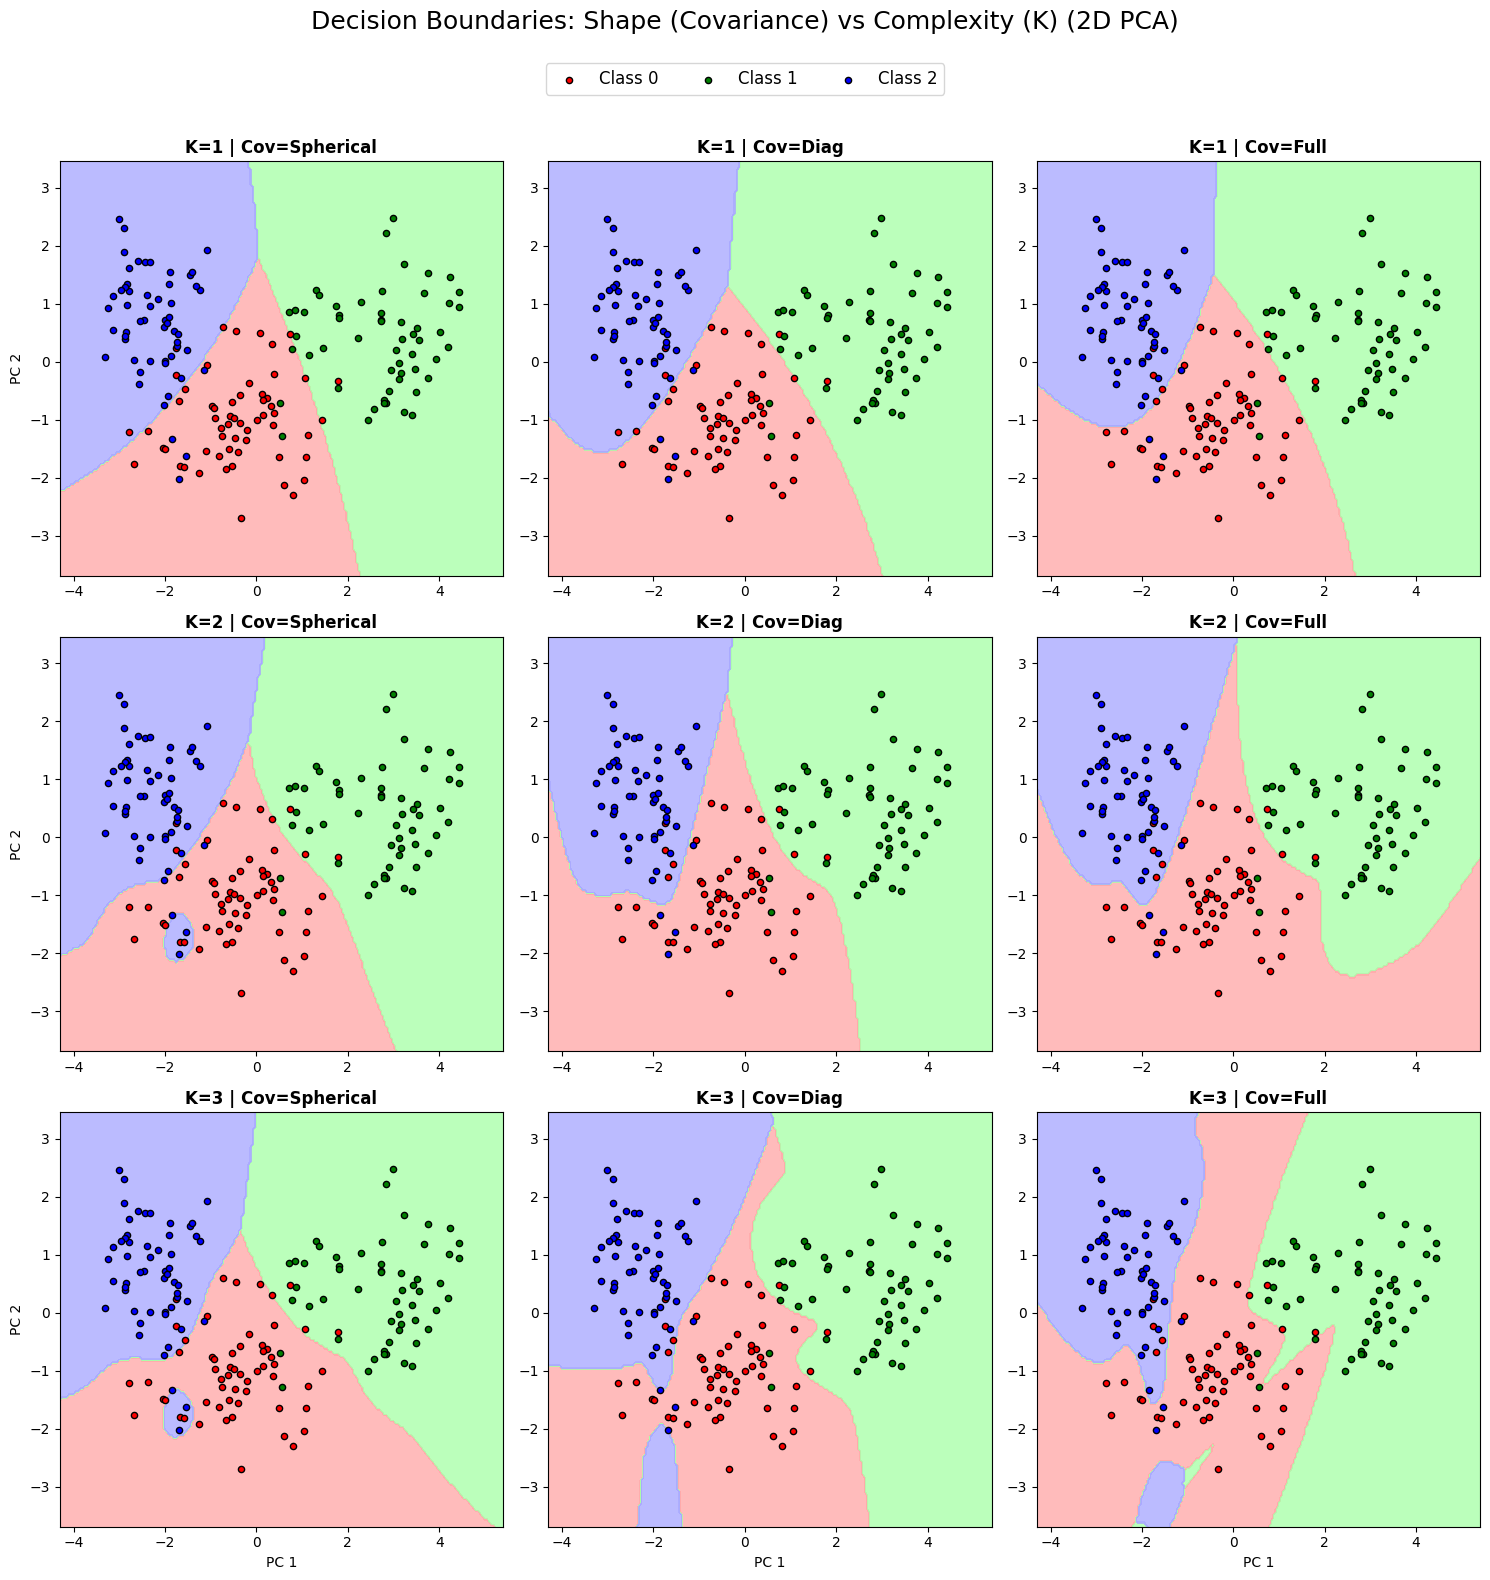

Execution and analysis complete.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.colors as mcolors
from sklearn.decomposition import PCA
import warnings

# Suppress runtime warnings for cleaner output (e.g., regarding log of zero)
warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# 1. Data Loading & Preprocessing
# ---------------------------------------------------------
print("Fetching and standardizing Wheat Seeds dataset...")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"
# Dataset uses varying amounts of whitespace
df = pd.read_csv(url, sep=r'\s+', header=None)

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values - 1 # Shift labels to 0, 1, 2

# Standardize features (Z-score normalization)
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X = (X - X_mean) / X_std

# Standard Manual Train/Test Split (80/20)
np.random.seed(42)
indices = np.random.permutation(len(X))
split_idx = int(len(X) * 0.8)
train_idx, test_idx = indices[:split_idx], indices[split_idx:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

# PCA Reduction for all 2D visual models
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# ---------------------------------------------------------
# 2. Mathematical Foundations (Custom GMM with BIC)
# ---------------------------------------------------------
def log_multivariate_normal(X, mean, cov):
    """Calculates the log probability density of a multivariate normal from scratch."""
    D = X.shape[1]
    # Small diagonal jitter for numerical stability
    cov = cov + np.eye(D) * 1e-6

    sign, logdet = np.linalg.slogdet(cov)
    inv_cov = np.linalg.inv(cov)

    diff = X - mean
    # Vectorized Mahalanobis distance computation
    maha = np.sum((diff @ inv_cov) * diff, axis=1)

    return -0.5 * (D * np.log(2 * np.pi) + logdet + maha)

class CustomGMM:
    def __init__(self, n_components=1, cov_type='full', max_iter=100, tol=1e-4):
        self.K = n_components
        self.cov_type = cov_type
        self.max_iter = max_iter
        self.tol = tol

    def _compute_n_parameters(self, D):
        """Calculates free parameters (p) based on covariance constraints."""
        if self.cov_type == 'spherical': cov_params = self.K
        elif self.cov_type == 'diag': cov_params = self.K * D
        elif self.cov_type == 'full': cov_params = self.K * D * (D + 1) / 2

        mean_params = self.K * D
        weight_params = self.K - 1
        return int(cov_params + mean_params + weight_params)

    def fit(self, X):
        N, D = X.shape
        np.random.seed(42)

        # Initialization: Random cluster means
        random_indices = np.random.choice(N, self.K, replace=False)
        self.means = X[random_indices].copy()

        # Initialize covariances as Identity matrices
        self.covs = np.array([np.eye(D) for _ in range(self.K)])

        # Uniform mixing weights
        self.pi = np.ones(self.K) / self.K

        log_likelihood_old = -np.inf

        for iteration in range(self.max_iter):
            # --- E-Step: Calculate Responsibilities ---
            log_resps = np.zeros((N, self.K))
            for k in range(self.K):
                # Log-domain calculation to handle small probabilities
                log_resps[:, k] = np.log(self.pi[k]) + log_multivariate_normal(X, self.means[k], self.covs[k])

            # Log-sum-exp normalization trick
            log_resp_norm = np.logaddexp.reduce(log_resps, axis=1)
            self.log_likelihood_ = np.sum(log_resp_norm)

            resps = np.exp(log_resps - log_resp_norm[:, np.newaxis])

            # Check for convergence
            if np.abs(self.log_likelihood_ - log_likelihood_old) < self.tol:
                break
            log_likelihood_old = self.log_likelihood_

            # --- M-Step: Update Parameters ---
            Nk = np.sum(resps, axis=0) # Total responsibility for component k
            self.pi = Nk / N

            for k in range(self.K):
                # Update Means
                self.means[k] = np.sum(resps[:, k, np.newaxis] * X, axis=0) / Nk[k]

                # Update Covariances based on shape constraints
                diff = X - self.means[k]
                cov = (resps[:, k, np.newaxis] * diff).T @ diff / Nk[k]

                if self.cov_type == 'full':
                    self.covs[k] = cov
                elif self.cov_type == 'diag':
                    self.covs[k] = np.diag(np.diag(cov)) # Force diagonal
                elif self.cov_type == 'spherical':
                    # Average of diagonal variances
                    self.covs[k] = np.eye(D) * np.mean(np.diag(cov))

        # Calculate BIC score for model selection
        p = self._compute_n_parameters(D)
        self.bic_ = p * np.log(N) - 2 * self.log_likelihood_

    def score_samples(self, X):
        """Returns the log-likelihood of samples under the fitted model."""
        N = X.shape[0]
        log_resps = np.zeros((N, self.K))
        for k in range(self.K):
            log_resps[:, k] = np.log(self.pi[k]) + log_multivariate_normal(X, self.means[k], self.covs[k])
        return np.logaddexp.reduce(log_resps, axis=1)

# ---------------------------------------------------------
# 3. Model Training & Parameter Exploration
# ---------------------------------------------------------
classes = np.unique(y_train)
k_values_all = [1, 2, 3, 4, 5]
k_values_visual = [1, 2, 3] # Restrict visual grids for clarity
cov_types = ['spherical', 'diag', 'full']

# Data storage for analysis
bic_scores = []
accuracy_surface_dict = {ctype: [] for ctype in cov_types}
accuracy_matrix = np.zeros((len(cov_types), len(k_values_all)))

# Storage for Figure 2 (Ellipsoid Grid) & Figure 3 (Boundary Grid)
models_2d_grid = {}

log_likelihood_heatmap_matrix = None # Specific LL heatmap data

print("Training high-dimensional and 2D models. This may take a few seconds...")

for i, cov_type in enumerate(cov_types):
    for j, K in enumerate(k_values_all):
        models_hd, models_2d = {}, {}
        total_bic = 0

        for c in classes:
            # 1. High-Dimensional Model (for Accuracy & BIC)
            X_c = X_train[y_train == c]
            gmm_hd = CustomGMM(n_components=K, cov_type=cov_type)
            gmm_hd.fit(X_c)
            models_hd[c] = gmm_hd
            total_bic += gmm_hd.bic_

            # 2. 2D Model (Strictly for Visualizations)
            X_c_pca = X_train_pca[y_train == c]
            gmm_2d = CustomGMM(n_components=K, cov_type=cov_type)
            gmm_2d.fit(X_c_pca)
            models_2d[c] = gmm_2d

        # Store 2D models for the visual grids (up to K=3)
        if K <= 3:
            models_2d_grid[(K, cov_type)] = models_2d

        # Store specific analytical data
        if cov_type == 'full':
            bic_scores.append(total_bic / len(classes))

        # Store Log-Likelihood heatmap data for a balanced K=2, Full model
        if cov_type == 'full' and K == 2:
            ll_scores = np.array([models_hd[c].score_samples(X_test) for c in classes]).T
            log_likelihood_heatmap_matrix = ll_scores

        # --- Testing: Generative Multiclass Classification ---
        preds = []
        for x in X_test:
            # Score this point against every class GMM
            scores = {c: models_hd[c].score_samples(x.reshape(1, -1))[0] for c in classes}
            # PREDICTION (Max Likelihood): Predict the class with the highest score
            # Fix: Using simple max(dict) logic to find the best class label key
            best_class = max(scores, key=scores.get)
            preds.append(best_class)

        acc = np.mean(np.array(preds) == y_test)
        accuracy_surface_dict[cov_type].append(acc)
        accuracy_matrix[i, j] = acc

# ---------------------------------------------------------
# 4. Visualization Utilities
# ---------------------------------------------------------
colors = ['r', 'g', 'b'] # Class colors

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draws a 2D confidence ellipse based on a covariance matrix."""
    ax = ax or plt.gca()
    # Singular Value Decomposition to get eigenvalues/eigenvectors
    U, s, Vt = np.linalg.svd(covariance)
    # Angle of rotation
    angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
    # Width and height (2 standard deviations for standard visual boundary)
    width, height = 2 * np.sqrt(s)
    for nsig in range(1, 3):
        ax.add_patch(Ellipse(position, nsig * width, nsig * height, angle=angle, **kwargs))

# Meshgrid setup for visual boundaries
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
mesh_points = np.c_[xx.ravel(), yy.ravel()]
cmap_light = mcolors.ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

# ---------------------------------------------------------
# 5. Visualization: Figure 1 (Analytical Plots & Heatmaps)
# ---------------------------------------------------------
print("Generating figure 1 (analytical suite)...")
fig1 = plt.figure(figsize=(16, 12))

# Plot A: BIC Curve ("Elbow" selection)
ax1 = plt.subplot(2, 3, 1)
ax1.plot(k_values_all, bic_scores, marker='o', color='purple', lw=2)
ax1.set_title('A. BIC Score vs Gaussians (Full Covariance)', fontweight='bold')
ax1.set_xlabel('Number of Gaussians (K)')
ax1.set_ylabel('Average BIC Score (Lower is Better)')
ax1.grid(True, alpha=0.3)

# Plot B: Accuracy Surface (Grouped Bar Chart)
ax2 = plt.subplot(2, 3, 2)
x_ticks = np.arange(len(cov_types))
width = 0.2
for i, K in enumerate([1, 2, 3]):
    accs = [accuracy_surface_dict[ctype][i] for ctype in cov_types]
    ax2.bar(x_ticks + i*width, accs, width, label=f'K={K}')
ax2.set_xticks(x_ticks + width)
ax2.set_xticklabels([c.capitalize() for c in cov_types])
ax2.set_title('B. Accuracy vs. Model Complexity', fontweight='bold')
ax2.set_ylabel('Test Accuracy')
ax2.set_ylim(0.7, 1.0)
ax2.legend(title="Complexity")

# Plot C: Log-Likelihood Heatmap (Confidence breakdown)
ax3 = plt.subplot(2, 3, 3)
im3 = ax3.imshow(log_likelihood_heatmap_matrix.T, aspect='auto', cmap='viridis')
ax3.set_title('C. Test Data Confidence Heatmap (K=2, Full)', fontweight='bold')
ax3.set_xlabel('Test Datapoint Index')
ax3.set_ylabel('Class GMM Model')
ax3.set_yticks([0, 1, 2])
plt.colorbar(im3, ax=ax3, label='Log-Likelihood Score')

# Plot D: Confusion Heatmap Matrix (NEW REQUIREMENT)


ax4 = plt.subplot(2, 3, (4, 6)) # Spans bottom row
im4 = ax4.imshow(accuracy_matrix, cmap='RdYlGn', interpolation='nearest', vmin=0.8)
ax4.set_title('D. Parameter Accuracy Heatmap (High-D Test Set)', fontweight='bold')
ax4.set_xticks(np.arange(len(k_values_all)))
ax4.set_xticklabels(k_values_all)
ax4.set_yticks(np.arange(len(cov_types)))
ax4.set_yticklabels([c.capitalize() for c in cov_types])
ax4.set_xlabel('Complexity (Number of Gaussians K)')
ax4.set_ylabel('Shape (Covariance Type)')

# Annotate accuracy values on the heatmap
for i in range(len(cov_types)):
    for j in range(len(k_values_all)):
        ax4.text(j, i, f'{accuracy_matrix[i, j]:.2f}', ha='center', va='center', color='black')
plt.colorbar(im4, ax=ax4, label='Accuracy')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Visualization: Figure 2 (Covariance Ellipsoids - NEW REQUIREMENT)
# ---------------------------------------------------------


print("Generating figure 2 (3x3 grid of covariance ellipsoid overlays)...")
fig2, axes2 = plt.subplots(3, 3, figsize=(15, 15))

for i, K in enumerate(k_values_visual):
    for j, cov_type in enumerate(cov_types):
        ax = axes2[i, j]
        models = models_2d_grid[(K, cov_type)]

        # Plot data points
        for c in classes:
            X_c = X_train_pca[y_train == c]
            ax.scatter(X_c[:, 0], X_c[:, 1], s=10, color=colors[c], alpha=0.3, label=f'Data Class {c}')

            # Plot Ellipsoids for each class component
            gmm_pca = models[c]
            for k in range(gmm_pca.K):
                draw_ellipse(gmm_pca.means[k], gmm_pca.covs[k], ax=ax, alpha=0.3, color=colors[c], lw=2)

        ax.set_title(f'K={K} | Cov={cov_type.capitalize()}', fontweight='bold')

        # Remove axis ticks for grid cleanliness
        ax.set_xticks([])
        ax.set_yticks([])

        if i == 2: ax.set_xlabel('PC 1')
        if j == 0: ax.set_ylabel('PC 2')

fig2.suptitle('Data Distribution Clustered by Gaussian Ellipsoids (2D PCA)', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Visualization: Figure 3 (3x3 Decision Boundaries)
# ---------------------------------------------------------
print("Generating figure 3 (3x3 grid of decision boundary meshplots)...")
fig3, axes3 = plt.subplots(3, 3, figsize=(15, 15))

for i, K in enumerate(k_values_visual):
    for j, cov_type in enumerate(cov_types):
        ax = axes3[i, j]
        models = models_2d_grid[(K, cov_type)]

        # Predict entire meshgrid to determine boundaries
        Z = []
        for point in mesh_points:
            scores = {c: models[c].score_samples(point.reshape(1, -1))[0] for c in classes}
            # PREDICTION (Max Likelihood): Predict the class with the highest score
            best_class = max(scores, key=scores.get)
            Z.append(best_class)

        Z = np.array(Z).reshape(xx.shape)

        # Plot boundary contours
        ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

        # Plot training points (colored by true class)
        for c in classes:
            ax.scatter(X_train_pca[y_train == c, 0], X_train_pca[y_train == c, 1],
                       c=colors[c], edgecolor='k', s=20, label=f'Class {c}')

        ax.set_title(f'K={K} | Cov={cov_type.capitalize()}', fontweight='bold')
        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())

        if i == 2: ax.set_xlabel('PC 1')
        if j == 0: ax.set_ylabel('PC 2')

handles, labels = axes3[0,0].get_legend_handles_labels()
fig3.legend(handles, labels, loc='upper center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, 1.02))
fig3.suptitle('Decision Boundaries: Shape (Covariance) vs Complexity (K) (2D PCA)', fontsize=18, y=1.05)

plt.tight_layout()
plt.show()
print("Execution and analysis complete.")